# 04 Preprocessing
Train-fitted isotropic normaliser and its inverse (so uncertainty converts back to millimetres), fixed-size clouds with masks, kNN, sampling and augmentation.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
from src.visualization.results import load_run
from src.data import dataset as ds, preprocessing as pp
model, norm, cfg, root = load_run(RUN)
print(norm)
x = np.random.default_rng(0).normal(size=(2000, 3)) * 60
print('round-trip max error (mm):', float(abs(norm.inverse(norm.forward(x)) - x).max()))
print('normalised std 0.02 ->', float(norm.std_to_mm(0.02)), 'mm (scale =', float(norm.scale), 'mm per unit)')

Normalizer(center=(0.4730412719251487, 6.388259603192072, -30.947829210568393), scale=78.10336788445446, fitted_on='42 base geometries')
round-trip max error (mm): 2.842170943040401e-14
normalised std 0.02 -> 1.562067357689089 mm (scale = 78.10336788445446 mm per unit)


In [3]:
d = ds.UncertafaceDataset(root, 'test', norm, 1024, 8, cache=False)
it = d[0]
print({k: tuple(v.shape) for k, v in it.items() if hasattr(v, 'shape')})
print('real points:', int(it['mask'].sum()), '/', len(it['mask']), '| missing fraction:', round(float(it['missing_fraction']), 3), '| severity record:', d.records[0]['observation']['severity'])

{'points': (1024, 3), 'mask': (1024,), 'knn_dist': (1024, 1), 'missing_fraction': (), 'face': (2095, 3), 'face_mm': (2095, 3)}
real points: 1024 / 1024 | missing fraction: 0.12 | severity record: mild


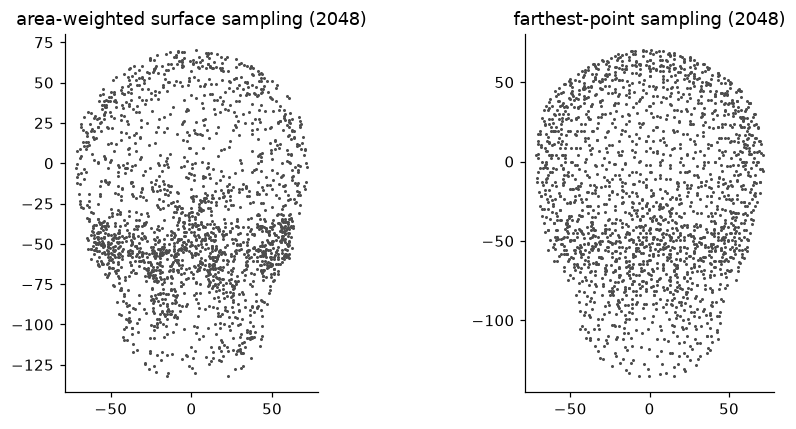

In [4]:
%matplotlib inline
from src.data import mesh_utils as mu
sv, sf = mu.load_mesh(str(pathlib.Path(root) / ('raw/generated/cranial_meshes/B%04d.ply' % d.records[0]['base_id'])))
rng = np.random.default_rng(0)
area = mu.sample_surface(sv, sf, 2048, rng)
idx = mu.farthest_point_sampling(sv, 2048) if hasattr(mu, 'farthest_point_sampling') else None
fig, ax = plt.subplots(1, 2 if idx is not None else 1, figsize=(9, 4))
ax = np.atleast_1d(ax)
ax[0].scatter(area[:, 0], area[:, 2], s=1, c='0.3'); ax[0].set_title('area-weighted surface sampling (2048)'); ax[0].set_aspect('equal')
if idx is not None: ax[1].scatter(sv[idx, 0], sv[idx, 2], s=1, c='0.3'); ax[1].set_title('farthest-point sampling (2048)'); ax[1].set_aspect('equal')
plt.tight_layout(); plt.show()

In [5]:
from src.data import augmentation as aug
print([n for n in dir(aug) if not n.startswith('_')][:12])
print('augmentations are applied in the training loader only (rotation, translation, jitter, dropout, density change, small warp, mirror).')

['Augmenter', 'annotations', 'np', 'rotation_matrix']
augmentations are applied in the training loader only (rotation, translation, jitter, dropout, density change, small warp, mirror).
